# 06A — SimCLR pooled validation analysis

This notebook analyses the frozen production run:

`simclr_resnet18_pooled_broad_natural_seed42_full_3408095`

The model was trained from scratch using a ResNet-18 backbone on the frozen
`pooled_broad_p80_10_10_v1` benchmark.

## Analysis policy

- The training run is treated as read-only.
- Development analysis uses the validation split only.
- The held-out test split remains untouched.
- Embeddings are joined to metadata using both `crystal_id` and
  `manifest_order`.
- Training objectives are interpreted only within the SimCLR model family.
- Clustering, retrieval, probing and confounder analysis will be added through
  the shared evaluation pipeline.


In [1]:
from __future__ import annotations

import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from plagnetplus.evaluation import (
    load_embedding_bundle,
    load_embedding_manifest,
    validate_embedding_manifest_alignment,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

IRP_ROOT = Path(
    os.environ.get(
        "IRP_ROOT",
        "/home/ars223/MSc-GEMS/IRP26",
    )
)

DEV_ROOT = IRP_ROOT / "plagnetplus-dev"

RUN_NAME = (
    "simclr_resnet18_pooled_broad_"
    "natural_seed42_full_3408095"
)

RUN_ROOT = (
    IRP_ROOT
    / "runs"
    / "hpc"
    / "simclr"
    / RUN_NAME
)

ANALYSIS_ROOT = (
    IRP_ROOT
    / "runs"
    / "analysis"
    / "simclr"
    / f"{RUN_NAME}_v1"
)

BENCHMARK_ROOT = (
    IRP_ROOT
    / "data"
    / "processed"
    / "plagnetplus"
    / "ssl_unified_v1"
    / "benchmarks"
    / "pooled_broad_p80_10_10_v1"
)

VALIDATION_MANIFEST = (
    BENCHMARK_ROOT
    / "manifests"
    / "crystals_validation.csv"
)

EMBEDDING_PATH = (
    RUN_ROOT
    / "embeddings"
    / "validation_backbone_embeddings.npz"
)

print("Run root:", RUN_ROOT)
print("Analysis root:", ANALYSIS_ROOT)
print("Validation manifest:", VALIDATION_MANIFEST)

for required_path in [
    RUN_ROOT / "COMPLETED.json",
    RUN_ROOT / "training_history.csv",
    EMBEDDING_PATH,
    VALIDATION_MANIFEST,
    ANALYSIS_ROOT / "metadata" / "embedding_integrity_summary.json",
    ANALYSIS_ROOT / "metadata" / "core_analysis_summary.json",
]:
    assert required_path.is_file(), required_path

print("NOTEBOOK INPUT PREFLIGHT: PASS")


Run root: /home/ars223/MSc-GEMS/IRP26/runs/hpc/simclr/simclr_resnet18_pooled_broad_natural_seed42_full_3408095
Analysis root: /home/ars223/MSc-GEMS/IRP26/runs/analysis/simclr/simclr_resnet18_pooled_broad_natural_seed42_full_3408095_v1
Validation manifest: /home/ars223/MSc-GEMS/IRP26/data/processed/plagnetplus/ssl_unified_v1/benchmarks/pooled_broad_p80_10_10_v1/manifests/crystals_validation.csv
NOTEBOOK INPUT PREFLIGHT: PASS


## 1. Run provenance

This section records the benchmark, model, training completion status,
embedding export, runtime and manifest fingerprint.


In [2]:
completed = json.loads(
    (RUN_ROOT / "COMPLETED.json").read_text(
        encoding="utf-8"
    )
)

resolved_config = json.loads(
    (
        RUN_ROOT
        / "metadata"
        / "resolved_config.json"
    ).read_text(
        encoding="utf-8"
    )
)

environment = json.loads(
    (
        RUN_ROOT
        / "metadata"
        / "environment.json"
    ).read_text(
        encoding="utf-8"
    )
)

provenance = pd.DataFrame(
    [
        ("Run name", completed["run_name"]),
        ("Status", completed["status"]),
        ("Method", completed["model"]["method"]),
        ("Backbone", completed["model"]["backbone"]),
        ("Initialisation", completed["model"]["initialization"]),
        (
            "Feature dimension",
            completed["model"]["feature_dimension"],
        ),
        (
            "Projection dimension",
            completed["model"]["projection_dimension"],
        ),
        (
            "Temperature",
            completed["model"]["temperature"],
        ),
        ("Completed epochs", completed["completed_epochs"]),
        ("History rows", completed["history_rows"]),
        ("Device", completed["device"]),
        (
            "Training elapsed hours",
            completed["elapsed_seconds"] / 3600.0,
        ),
        ("Benchmark", completed["benchmark_id"]),
        (
            "Manifest fingerprint",
            completed["manifest_fingerprint_sha256"],
        ),
        (
            "Checkpoint SHA-256",
            completed["checkpoint"]["sha256"],
        ),
        (
            "Embedding SHA-256",
            completed["validation_embeddings"]["sha256"],
        ),
        (
            "Embedding shape",
            tuple(completed["validation_embeddings"]["shape"]),
        ),
    ],
    columns=["Field", "Value"],
)

display(provenance)

assert completed["status"] == "PASS"
assert completed["completed_epochs"] == 100
assert completed["history_rows"] == 200
assert completed["validation_embeddings"]["shape"] == [14919, 512]

print("RUN PROVENANCE: PASS")


,Field,Value
0,Run name,simclr_resnet18_pooled_broad_natural_seed42_fu...
1,Status,PASS
2,Method,simclr
3,Backbone,resnet18
4,Initialisation,scratch
5,Feature dimension,512
6,Projection dimension,128
7,Temperature,0.2
8,Completed epochs,100
9,History rows,200


RUN PROVENANCE: PASS


## 2. Training history

The SimCLR NT-Xent objective is useful for comparing SimCLR runs using the
same implementation, but it must not be ranked directly against the losses
from SimSiam, DeepCluster, SwAV or DINOv2.


In [3]:
history = pd.read_csv(
    RUN_ROOT / "training_history.csv"
)

training_summary = json.loads(
    (
        ANALYSIS_ROOT
        / "metadata"
        / "training_history_summary.json"
    ).read_text(
        encoding="utf-8"
    )
)

display(
    pd.DataFrame(
        [
            ("Completed epochs", training_summary["completed_epochs"]),
            (
                "Best validation epoch",
                training_summary["best_validation_epoch"],
            ),
            (
                "Best validation loss",
                training_summary["best_validation_loss"],
            ),
            (
                "Final train loss",
                training_summary["final_train_loss"],
            ),
            (
                "Final validation loss",
                training_summary["final_validation_loss"],
            ),
            (
                "Final train-validation gap",
                training_summary["final_train_validation_gap"],
            ),
            (
                "Final-10 validation loss SD",
                training_summary[
                    "validation_loss_standard_deviation_final_10_epochs"
                ],
            ),
            (
                "Mean train epoch seconds",
                training_summary["mean_train_epoch_seconds"],
            ),
            (
                "Mean validation epoch seconds",
                training_summary["mean_validation_epoch_seconds"],
            ),
        ],
        columns=["Metric", "Value"],
    )
)

history.tail(10)


,Metric,Value
0,Completed epochs,100.000000
1,Best validation epoch,96.000000
2,Best validation loss,1.632181
3,Final train loss,1.552659
4,Final validation loss,1.634463
5,Final train-validation gap,0.081804
6,Final-10 validation loss SD,0.001343
7,Mean train epoch seconds,244.500350
8,Mean validation epoch seconds,44.775493


,epoch,split,loss,positive_pair_accuracy,learning_rate,batches,images,seconds
190,96,train,1.552629,1.0,1.492723e-06,397,101632,244.344041
191,96,validation,1.632181,1.0,1.492723e-06,59,14919,44.074630
192,97,train,1.552672,1.0,8.402676e-07,397,101632,245.011161
193,97,validation,1.634517,1.0,8.402676e-07,59,14919,45.135296
194,98,train,1.552638,1.0,3.736462e-07,397,101632,242.034674
195,98,validation,1.636446,1.0,3.736462e-07,59,14919,44.144641
196,99,train,1.552679,1.0,9.344066e-08,397,101632,244.022369
197,99,validation,1.635965,1.0,9.344066e-08,59,14919,44.738975
198,100,train,1.552659,1.0,0.000000e+00,397,101632,248.330637
199,100,validation,1.634463,1.0,0.000000e+00,59,14919,46.161747


training_and_validation_loss.png


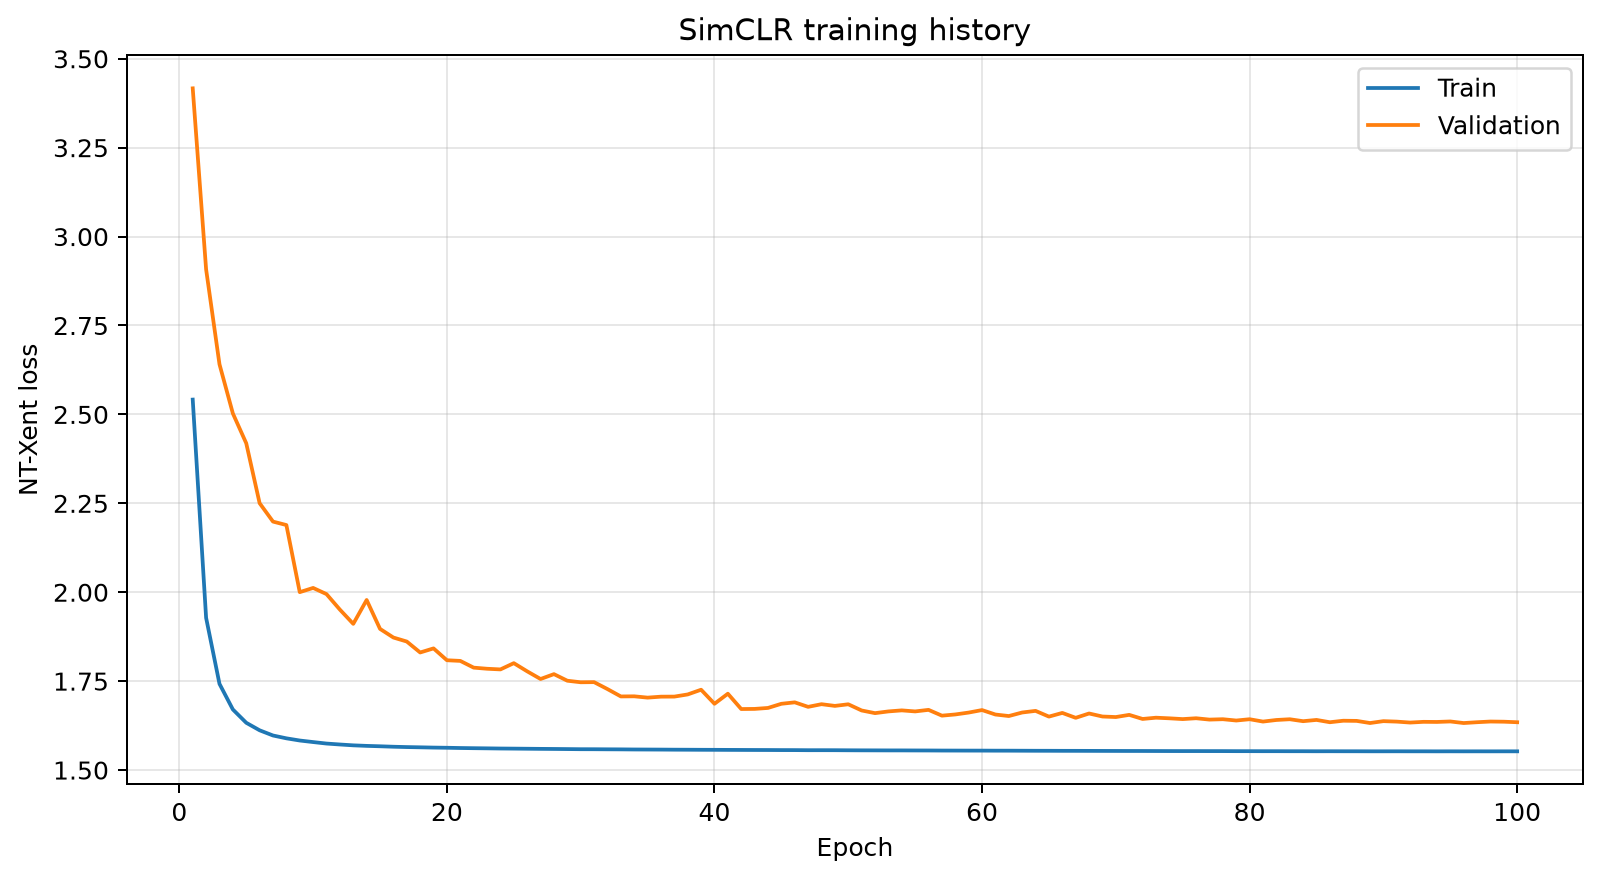

learning_rate.png


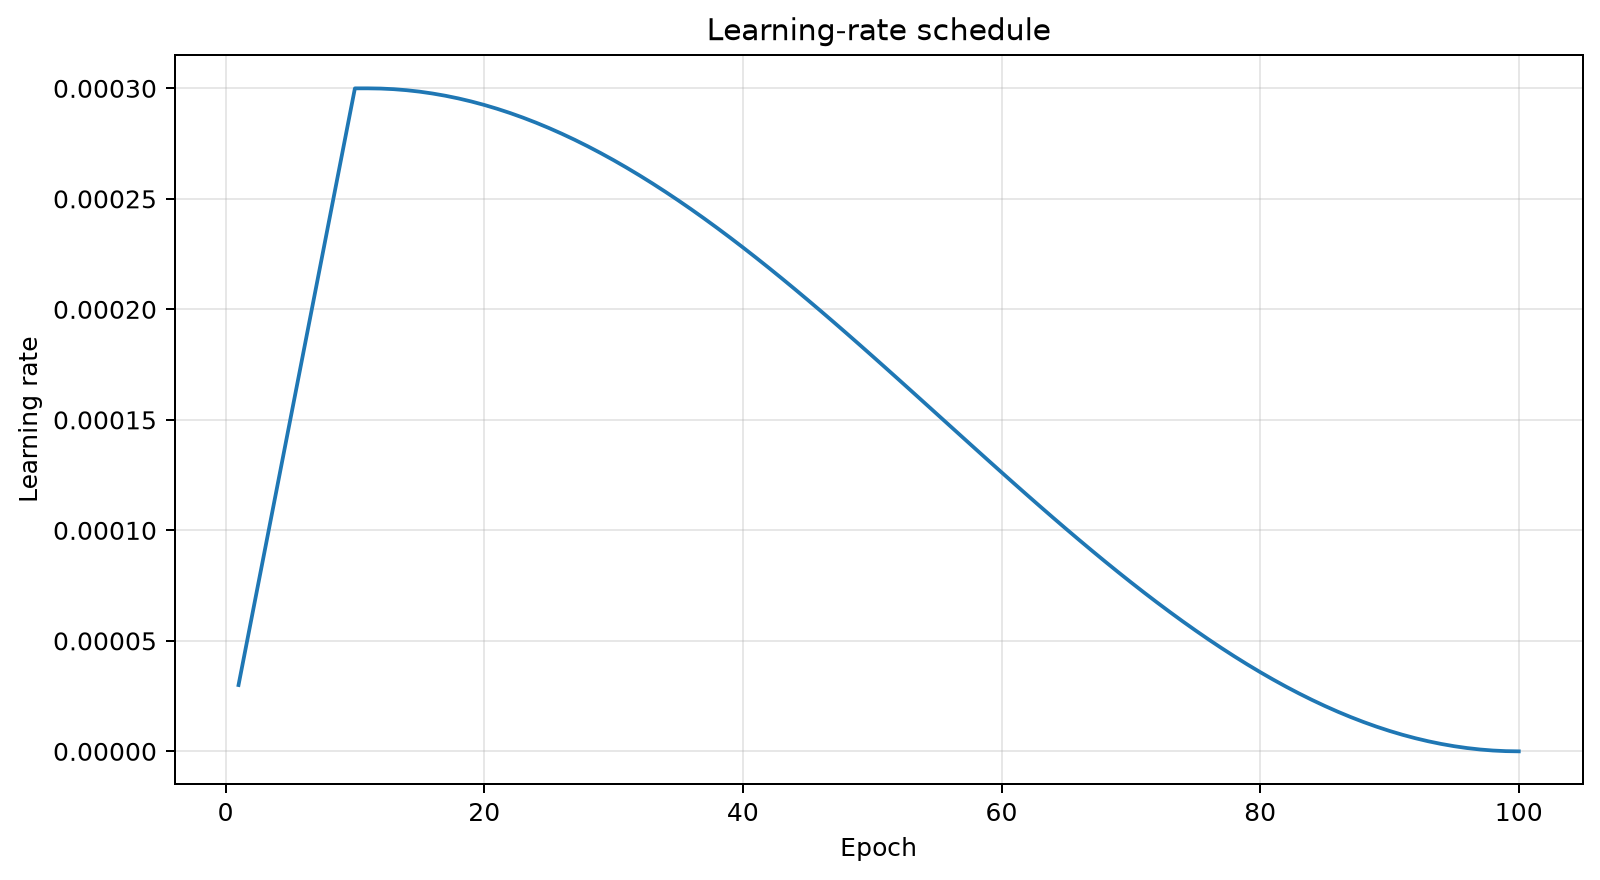

positive_pair_accuracy.png


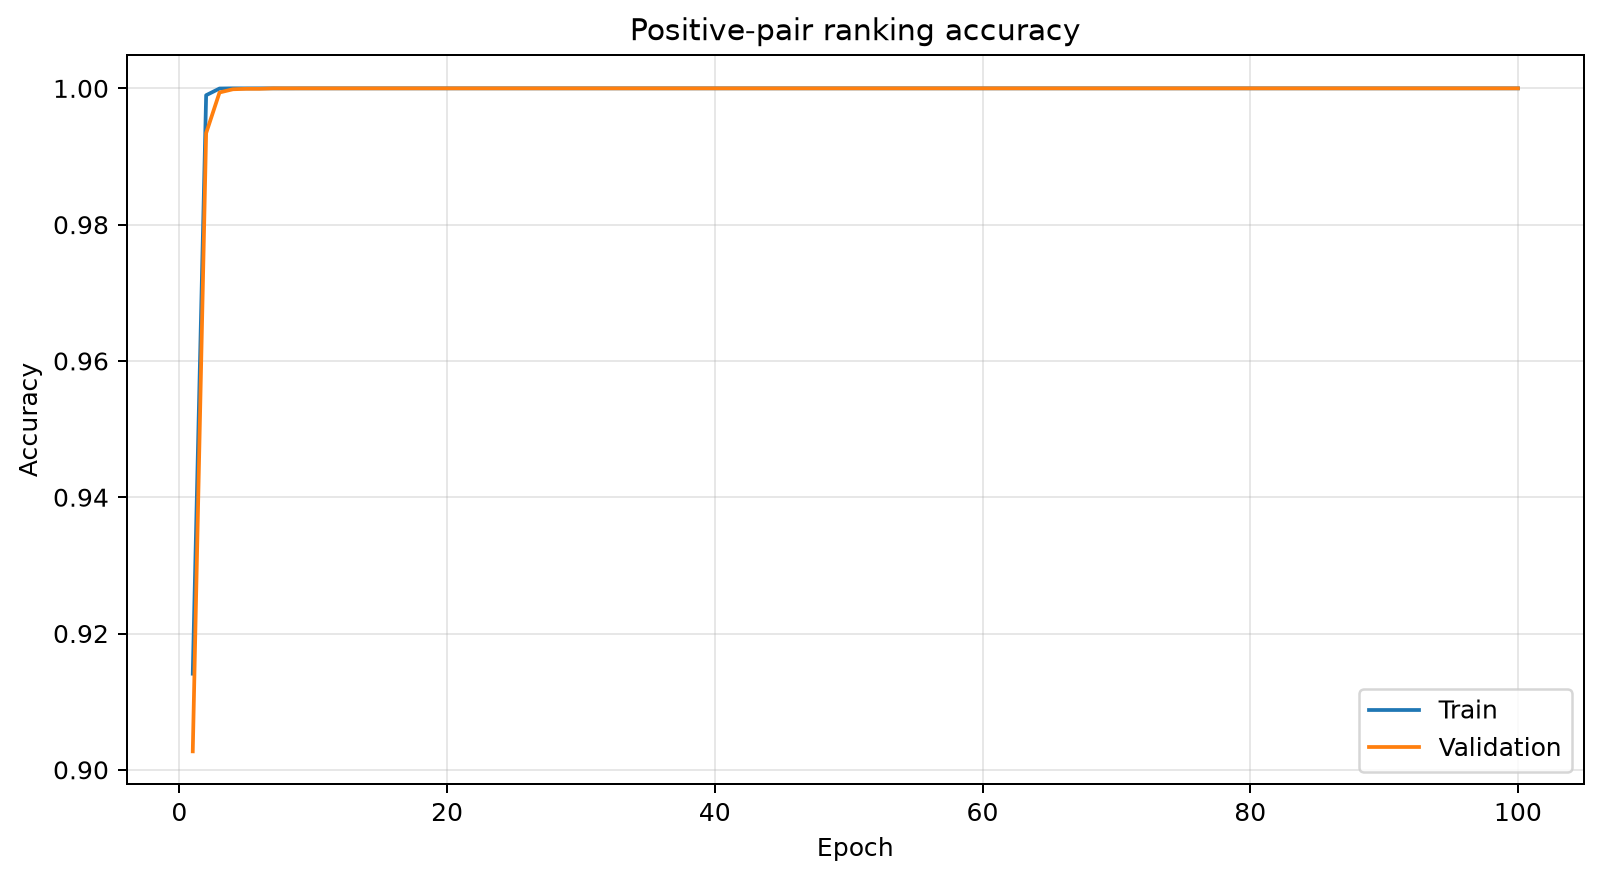

epoch_runtime.png


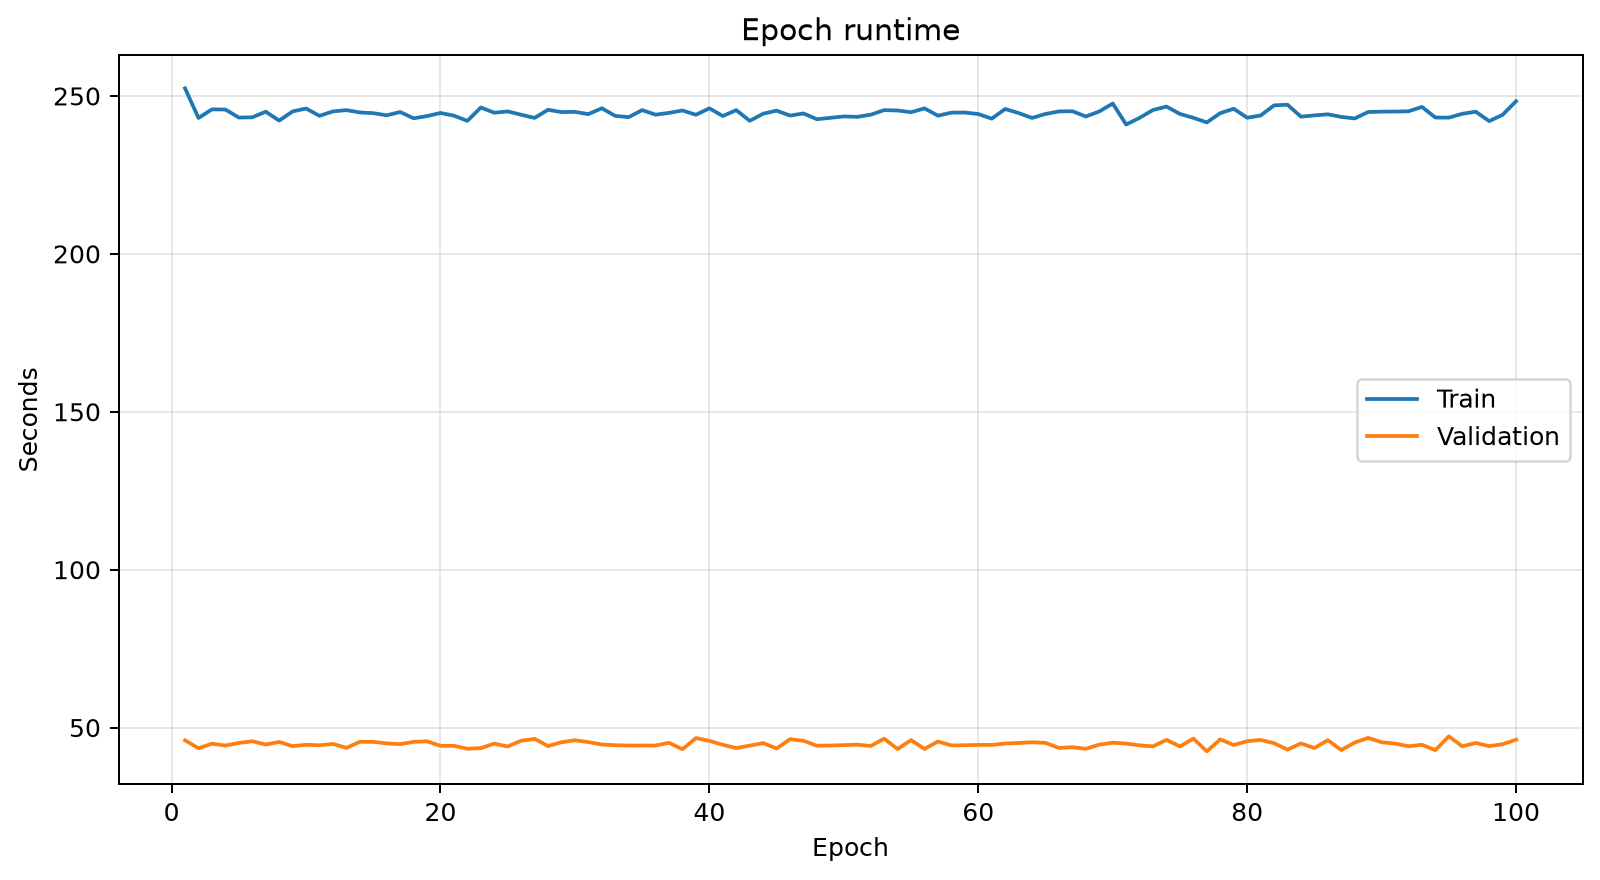

In [4]:
for figure_name in [
    "training_and_validation_loss.png",
    "learning_rate.png",
    "positive_pair_accuracy.png",
    "epoch_runtime.png",
]:
    figure_path = (
        ANALYSIS_ROOT
        / "figures"
        / figure_name
    )

    print(figure_name)
    display(Image(filename=str(figure_path)))


### Training interpretation

The positive-pair ranking accuracy should not be interpreted as a complete
measure of representation quality. A model may identify positive pairs while
still learning an anisotropic, redundant or acquisition-dominated embedding.

The shared comparison will therefore rely on embedding health, clustering
separation, clustering stability, cross-sample retrieval, group-aware probes
and acquisition-confounder measurements.


## 3. Embedding integrity and representation health

This section checks whether the exported 512-dimensional validation
representations are finite, unique, correctly aligned and non-collapsed.


In [5]:
integrity_report = json.loads(
    (
        ANALYSIS_ROOT
        / "metadata"
        / "embedding_integrity_summary.json"
    ).read_text(
        encoding="utf-8"
    )
)

health = integrity_report["representation_health"]

health_table = pd.DataFrame(
    [
        ("Rows", health["row_count"]),
        ("Feature dimension", health["feature_dimension"]),
        ("All finite", health["all_finite"]),
        (
            "Zero-variance dimensions",
            health["zero_variance_dimensions"],
        ),
        (
            "Near-zero-variance dimensions",
            health["near_zero_variance_dimensions"],
        ),
        (
            "Exact duplicate embedding rows",
            health["exact_duplicate_embedding_rows"],
        ),
        ("Zero-norm rows", health["zero_norm_rows"]),
        ("Mean embedding norm", health["mean_embedding_norm"]),
        (
            "Embedding norm standard deviation",
            health["embedding_norm_standard_deviation"],
        ),
        ("Effective rank", health["effective_rank"]),
        (
            "Normalised effective rank",
            health["normalised_effective_rank"],
        ),
        (
            "Sampled mean pairwise cosine similarity",
            health[
                "sampled_mean_pairwise_cosine_similarity"
            ],
        ),
    ],
    columns=["Metric", "Value"],
)

display(health_table)

assert integrity_report["status"] == "PASS"
assert health["all_finite"]
assert health["exact_duplicate_embedding_rows"] == 0
assert health["zero_norm_rows"] == 0
assert health["zero_variance_dimensions"] == 0

print("EMBEDDING HEALTH GATE: PASS")


,Metric,Value
0,Rows,14919
1,Feature dimension,512
2,All finite,True
3,Zero-variance dimensions,0
4,Near-zero-variance dimensions,0
5,Exact duplicate embedding rows,0
6,Zero-norm rows,0
7,Mean embedding norm,8.79017
8,Embedding norm standard deviation,0.368996
9,Effective rank,33.680197


EMBEDDING HEALTH GATE: PASS


### Representation-health interpretation

The embedding has not completely collapsed: every row is unique, every
dimension varies and no vector has zero norm.

However, the effective rank and random-pair cosine similarity indicate a
strongly anisotropic representation. Most crystals share a substantial common
direction in the original feature space.

For that reason:

- primary clustering will use centred PCA features;
- retrieval will report raw cosine similarity;
- centred-cosine retrieval will be retained as a sensitivity analysis;
- effective rank will remain a standard cross-model diagnostic.


## 4. Exact metadata alignment

The embedding export is joined to the validation manifest using both
`crystal_id` and `manifest_order`. Row-position assumptions alone are not
accepted.


In [6]:
bundle = load_embedding_bundle(
    EMBEDDING_PATH,
    expected_feature_dimension=512,
)

manifest = load_embedding_manifest(
    VALIDATION_MANIFEST
)

alignment = validate_embedding_manifest_alignment(
    bundle,
    manifest,
)

display(
    pd.DataFrame(
        alignment.items(),
        columns=["Check", "Value"],
    )
)

assert alignment["row_count"] == 14919
assert alignment["ids_aligned"]
assert alignment["manifest_orders_aligned"]

print("VALIDATION MANIFEST ALIGNMENT: PASS")


,Check,Value
0,row_count,14919
1,feature_dimension,512
2,ids_aligned,True
3,manifest_orders_aligned,True
4,embedding_id_duplicates,0
5,embedding_order_duplicates,0
6,manifest_id_duplicates,0
7,manifest_order_duplicates,0


VALIDATION MANIFEST ALIGNMENT: PASS


## 5. PCA dimensionality

PCA is fitted only on the validation embeddings for exploratory validation
analysis. The selected 50-dimensional PCA representation is used for the
standard clustering comparison.

The held-out test set remains untouched.


In [7]:
pca_summary = json.loads(
    (
        ANALYSIS_ROOT
        / "metadata"
        / "pca_summary.json"
    ).read_text(
        encoding="utf-8"
    )
)

pca_variance = pd.read_csv(
    ANALYSIS_ROOT
    / "tables"
    / "pca_explained_variance.csv"
)

display(
    pd.DataFrame(
        pca_summary.items(),
        columns=["Metric", "Value"],
    )
)

display(
    pca_variance.head(20)
)


,Metric,Value
0,components_for_50_percent_variance,9.000000
1,components_for_80_percent_variance,20.000000
2,components_for_90_percent_variance,27.000000
3,components_for_95_percent_variance,34.000000
4,components_for_99_percent_variance,99.000000
5,input_dimension,512.000000
6,pc1_explained_variance_ratio,0.082319
7,pc2_explained_variance_ratio,0.077514
8,pc3_explained_variance_ratio,0.069870
9,retained_components,50.000000


,component,eigenvalue,explained_variance_ratio,cumulative_explained_variance
0,1,0.475827,0.082319,0.082319
1,2,0.448053,0.077514,0.159834
2,3,0.403866,0.069870,0.229704
3,4,0.383761,0.066392,0.296095
4,5,0.328198,0.056779,0.352874
5,6,0.308973,0.053453,0.406328
6,7,0.277128,0.047944,0.454271
7,8,0.242954,0.042032,0.496303
8,9,0.206283,0.035687,0.531991
9,10,0.198920,0.034414,0.566404


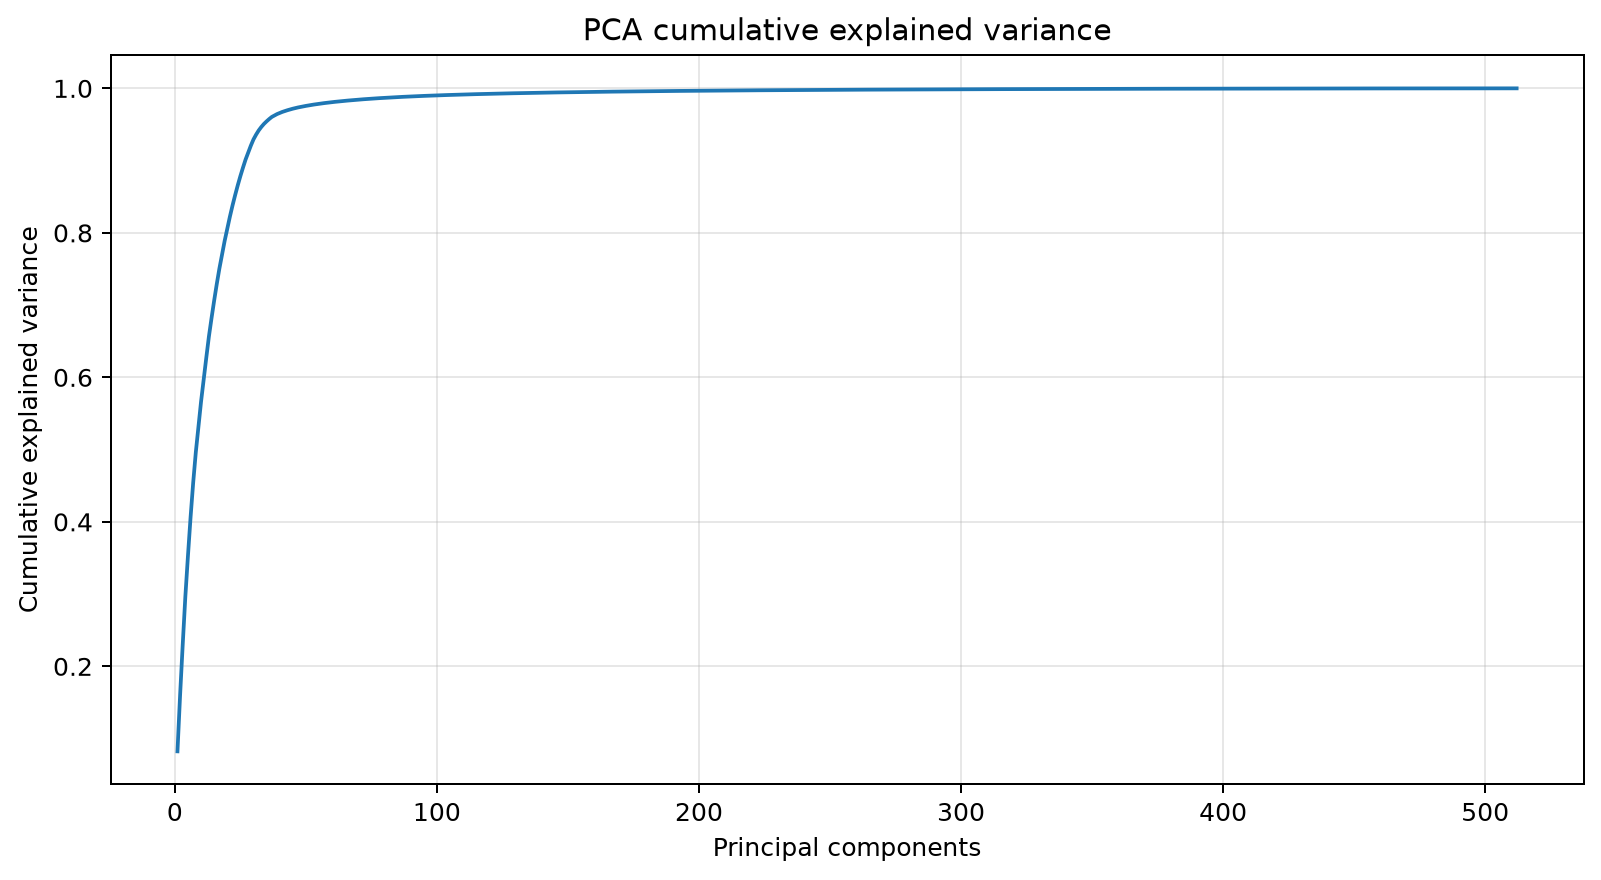

In [8]:
display(
    Image(
        filename=str(
            ANALYSIS_ROOT
            / "figures"
            / "pca_cumulative_variance.png"
        )
    )
)


## 6. PCA views by locality

These plots are descriptive rather than proof of geological populations.
Locality separation may contain both geological signal and acquisition or
sample-preparation effects.


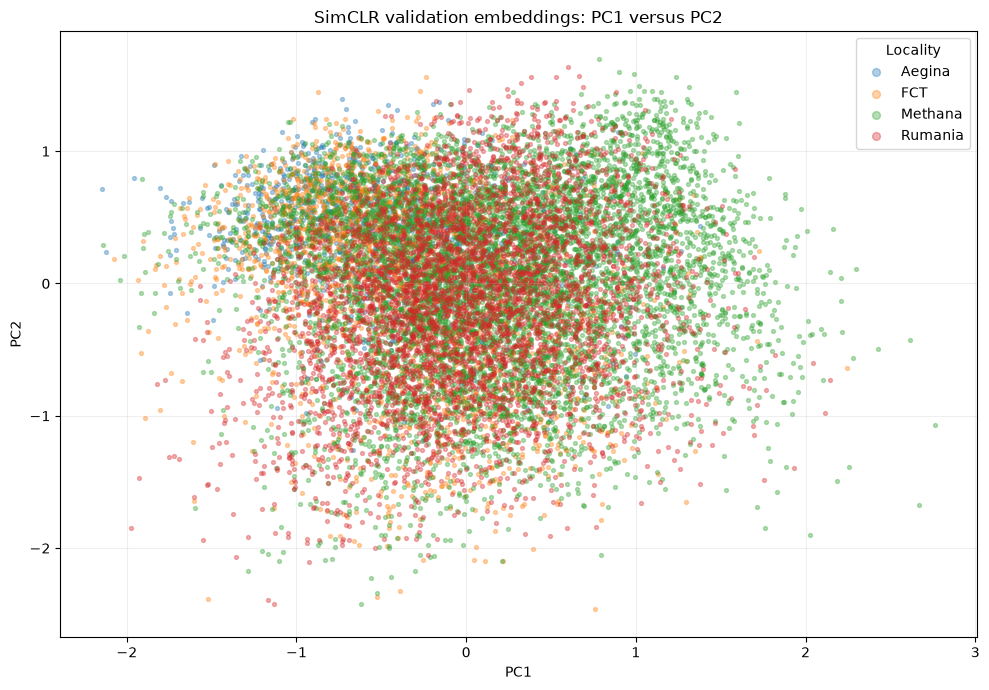

In [9]:
with np.load(
    ANALYSIS_ROOT
    / "embeddings"
    / "validation_pca_50.npz",
    allow_pickle=False,
) as payload:
    pca_features = np.asarray(
        payload["features"]
    )
    pca_crystal_ids = np.asarray(
        payload["crystal_ids"]
    ).astype(str)
    pca_manifest_orders = np.asarray(
        payload["manifest_orders"]
    ).astype(np.int64)

assert pca_features.shape == (14919, 50)
assert np.isfinite(pca_features).all()
assert np.array_equal(
    pca_crystal_ids,
    bundle.crystal_ids,
)
assert np.array_equal(
    pca_manifest_orders,
    bundle.manifest_orders,
)

plot_data = manifest.copy()
plot_data["PC1"] = pca_features[:, 0]
plot_data["PC2"] = pca_features[:, 1]
plot_data["PC3"] = pca_features[:, 2]

figure, axis = plt.subplots(
    figsize=(10, 7)
)

for locality, group in plot_data.groupby(
    "locality",
    observed=True,
    sort=True,
):
    axis.scatter(
        group["PC1"],
        group["PC2"],
        s=8,
        alpha=0.35,
        label=str(locality),
    )

axis.set_title(
    "SimCLR validation embeddings: PC1 versus PC2"
)
axis.set_xlabel("PC1")
axis.set_ylabel("PC2")
axis.legend(
    title="Locality",
    markerscale=2,
)
axis.grid(
    True,
    alpha=0.2,
)

figure.tight_layout()
plt.show()


In [10]:
locality_counts = (
    manifest.groupby(
        "locality",
        observed=True,
    )
    .size()
    .rename("validation_crystals")
    .sort_values(ascending=False)
    .to_frame()
)

display(locality_counts)

available_metadata = [
    column
    for column in [
        "locality",
        "sample_id",
        "split_group_id",
        "acquisition_id",
        "image_root_key",
        "source_filename",
        "mask_area_fraction",
        "foreground_fraction",
    ]
    if column in manifest.columns
]

print("Available comparison metadata:")
for column in available_metadata:
    print(" -", column)


,validation_crystals
locality,
Methana,7071
Rumania,4440
FCT,2314
Aegina,1094


Available comparison metadata:
 - locality
 - sample_id
 - split_group_id
 - acquisition_id
 - image_root_key


## 7. Current conclusions

At this stage the production SimCLR run has passed:

- scheduler and training completion checks;
- checkpoint and embedding hash verification;
- exact validation-manifest alignment;
- finite-value and duplicate-vector checks;
- training-history validation;
- deterministic PCA preparation.

The next shared evaluation stages are:

1. clustering separation across fixed values of \(k\);
2. clustering stability across fixed seeds;
3. cross-sample nearest-neighbour retrieval;
4. group-aware locality probing;
5. acquisition-confounder probing;
6. registration in the shared model-comparison database.

No test-set result is generated by this notebook.


## Final frozen SimCLR evaluation

This section reads the immutable analysis summary and experiment
registry produced after the full SimCLR evaluation.

The expert-reviewed cross-sample texture retrieval score remains
pending and is deliberately not replaced by the automatic FCT-only
diagnostic. The test split remains frozen.


In [11]:
from pathlib import Path
import json
import os

import pandas as pd
from IPython.display import display


IRP_ROOT = Path(
    os.environ.get(
        "IRP_ROOT",
        "/home/ars223/MSc-GEMS/IRP26",
    )
)

SIMCLR_RUN_NAME = (
    "simclr_resnet18_pooled_broad_natural_seed42_full_3408095"
)

SIMCLR_ANALYSIS_ROOT = (
    IRP_ROOT
    / "runs"
    / "analysis"
    / "simclr"
    / f"{SIMCLR_RUN_NAME}_v1"
)

summary_path = (
    SIMCLR_ANALYSIS_ROOT
    / "analysis_summary.json"
)

summary = json.loads(
    summary_path.read_text(
        encoding="utf-8"
    )
)

assert summary["status"] == "PASS"
assert (
    summary["benchmark"][
        "test_split_accessed"
    ]
    is False
)

comparison = summary[
    "comparison_metrics"
]

comparison_table = pd.DataFrame(
    [
        {
            "Model": "SimCLR ResNet-18",
            "Median silhouette": comparison[
                "median_silhouette"
            ],
            "Median stability ARI": comparison[
                "median_stability_ari"
            ],
            "Automatic FCT cross-sample P@10": comparison[
                "automatic_fct_cross_sample_precision_at_10_raw"
            ],
            "Expert texture P@10": comparison[
                "expert_retrieval_precision_at_10"
            ],
            "Locality macro-F1": comparison[
                "locality_macro_f1"
            ],
            "Source-image enrichment@10": comparison[
                "source_image_enrichment_at_10_raw"
            ],
            "Validation effective rank": comparison[
                "validation_effective_rank"
            ],
            "GPU hours": comparison[
                "gpu_hours"
            ],
        }
    ]
)

display(
    comparison_table.round(4)
)


,Model,Median silhouette,Median stability ARI,Automatic FCT cross-sample P@10,Expert texture P@10,Locality macro-F1,Source-image enrichment@10,Validation effective rank,GPU hours
0,SimCLR ResNet-18,0.0695,0.6111,0.0912,None,0.4731,2.1985,33.6802,8.0493


In [12]:
locality_table = pd.DataFrame(
    summary[
        "locality_probe"
    ]["per_class"]
)

display(
    locality_table.round(
        {
            "precision": 4,
            "recall": 4,
            "f1": 4,
        }
    )
)

probe = summary[
    "locality_probe"
]

print(
    "Macro-F1:",
    round(
        probe["macro_f1"],
        4,
    ),
)

print(
    "Balanced accuracy:",
    round(
        probe["balanced_accuracy"],
        4,
    ),
)

print(
    "Overall accuracy:",
    round(
        probe["accuracy"],
        4,
    ),
)

print(
    "Majority baseline accuracy:",
    round(
        probe[
            "majority_baseline_accuracy"
        ],
        4,
    ),
)


,f1,locality,precision,recall,support
0,0.5524,Aegina,0.4629,0.6846,1094
1,0.6035,FCT,0.4831,0.8038,2314
2,0.6802,Methana,0.6916,0.6692,7071
3,0.0563,Rumania,0.4149,0.0302,4440


Macro-F1: 0.4731
Balanced accuracy: 0.547
Overall accuracy: 0.501
Majority baseline accuracy: 0.474


In [13]:
training = summary["training"]
representation = summary[
    "representation"
]

training_table = pd.DataFrame(
    [
        {
            "Completed epochs": training[
                "completed_epochs"
            ],
            "Final train loss": training[
                "final_train_loss"
            ],
            "Final validation loss": training[
                "final_validation_loss"
            ],
            "Best validation epoch": training[
                "best_validation_epoch"
            ],
            "Train effective rank": representation[
                "train"
            ]["effective_rank"],
            "Validation effective rank": representation[
                "validation"
            ]["effective_rank"],
            "Train mean cosine": representation[
                "train"
            ][
                "sampled_mean_pairwise_cosine_similarity"
            ],
            "Validation mean cosine": representation[
                "validation"
            ][
                "sampled_mean_pairwise_cosine_similarity"
            ],
        }
    ]
)

display(
    training_table.round(4)
)


,Completed epochs,Final train loss,Final validation loss,Best validation epoch,Train effective rank,Validation effective rank,Train mean cosine,Validation mean cosine
0,100,1.5527,1.6345,96,39.5223,33.6802,0.9252,0.9267


In [14]:
interpretation = summary[
    "interpretation"
]

print(
    "Test split remains frozen:",
    interpretation[
        "test_split_remains_frozen"
    ],
)

print(
    "Expert retrieval review pending:",
    interpretation[
        "expert_retrieval_review_pending"
    ],
)

print(
    "Representation anisotropic:",
    interpretation[
        "representation_anisotropic"
    ],
)

print(
    "Global cluster separation weak:",
    interpretation[
        "global_cluster_separation_weak"
    ],
)

print(
    "Cross-sample retrieval signal modest:",
    interpretation[
        "cross_sample_retrieval_signal_modest"
    ],
)

print(
    "Sample/acquisition confounding requires caution:",
    interpretation[
        "sample_and_acquisition_confounding_requires_caution"
    ],
)

print(
    "Single composite score used:",
    interpretation[
        "single_composite_score_used"
    ],
)


Test split remains frozen: True
Expert retrieval review pending: True
Representation anisotropic: True
Global cluster separation weak: True
Cross-sample retrieval signal modest: True
Sample/acquisition confounding requires caution: True
Single composite score used: False


In [15]:
import sqlite3


registry_path = (
    IRP_ROOT
    / "runs"
    / "analysis"
    / "registry"
    / "plagnetplus_experiments.sqlite"
)

connection = sqlite3.connect(
    registry_path
)

try:
    registry_row = pd.read_sql_query(
        '''
        SELECT
            model_id,
            method,
            backbone,
            status,
            median_silhouette_across_k,
            median_stability_ari_across_k,
            automatic_fct_cross_sample_p10_raw,
            expert_cross_sample_texture_p10,
            locality_macro_f1,
            source_image_enrichment_at10_raw,
            validation_effective_rank,
            gpu_hours,
            test_split_accessed
        FROM experiments
        WHERE model_id = ?
        ''',
        connection,
        params=(
            SIMCLR_RUN_NAME,
        ),
    )
finally:
    connection.close()

assert len(registry_row) == 1
assert (
    registry_row.loc[
        0,
        "status",
    ]
    == "PASS"
)
assert (
    registry_row.loc[
        0,
        "test_split_accessed",
    ]
    == 0
)

display(
    registry_row.round(4)
)


,model_id,method,backbone,status,median_silhouette_across_k,median_stability_ari_across_k,automatic_fct_cross_sample_p10_raw,expert_cross_sample_texture_p10,locality_macro_f1,source_image_enrichment_at10_raw,validation_effective_rank,gpu_hours,test_split_accessed
0,simclr_resnet18_pooled_broad_natural_seed42_fu...,simclr,resnet18,PASS,0.0695,0.6111,0.0912,None,0.4731,2.1985,33.6802,8.0493,0


### Interpretation

The SimCLR representation is non-collapsed but strongly anisotropic.
Clustering has weak global separation despite moderate multi-seed
stability. Most unrestricted locality retrieval is explained by
same-sample neighbours.

The FCT-only automatic cross-sample diagnostic indicates modest
cross-sample signal. The locality probe transfers unevenly between
held-out physical samples, with especially poor Rumania recall.
These metadata associations must not be treated as proof of
geologically meaningful crystal populations.

The expert-reviewed texture retrieval assessment remains pending.
